# HCP Young Adult — Dataset Overview

This notebook introduces the HCP YA subject list and explains what data files are available locally.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import os

CSV_PATH = '../data/HCP_YA_subjects_2026_04_30_00_43_32.csv'
DATA_ROOT = '../data/'

df = pd.read_csv(CSV_PATH)
print(f'Subjects: {len(df)}   Columns: {df.shape[1]}')

Subjects: 1206   Columns: 261


## 1. Column Groups

The 261 columns fall into these categories:

| Group | Count | Description |
|---|---|---|
| Subject info | 8 | ID, release, age, gender, scan availability |
| NIH Toolbox cognitive | 25 | 8 tasks × (unadj + age-adj) + 4 composite scores |
| Delay discounting | 14 | Subjective value at different delays (200/$40K) |
| Attention / memory tasks | 13 | VSPLOT, SCPT, IWRD |
| FreeSurfer volumes | 59 | Whole-brain and subcortical volumes |
| FreeSurfer thickness | 68 | Cortical thickness per region (L+R) |
| FreeSurfer area | 68 | Cortical surface area per region (L+R) |
| FreeSurfer misc | 6 | eTIV ratios, defect holes |

In [2]:
# Define column groups
info_cols = ['Subject', 'Release', 'Acquisition', 'Gender', 'Age',
             '3T_Full_MR_Compl', '7T_Full_MR_Compl', 'MEG_FullProt_Compl']

cog_tasks = ['PicSeq', 'CardSort', 'Flanker', 'ReadEng', 'PicVocab',
             'ProcSpeed', 'ListSort']
cog_cols  = [c for c in df.columns if any(c.startswith(t) for t in cog_tasks)]
cog_cols += ['PMAT24_A_CR', 'PMAT24_A_SI', 'PMAT24_A_RTCR']
cog_comp  = [c for c in df.columns if c.startswith('Cog') and 'Comp' in c]

ddisc_cols  = [c for c in df.columns if c.startswith('DDisc_')]
other_cols  = [c for c in df.columns if c.startswith(('VSPLOT', 'SCPT', 'IWRD'))]

fs_vol   = [c for c in df.columns if c.startswith('FS_') and '_Vol' in c]
fs_thck  = [c for c in df.columns if c.startswith('FS_') and '_Thck' in c]
fs_area  = [c for c in df.columns if c.startswith('FS_') and '_Area' in c]
fs_other = [c for c in df.columns if c.startswith('FS_') and c not in fs_vol + fs_thck + fs_area]

groups = {
    'Subject info': info_cols,
    'NIH Toolbox tasks': cog_cols,
    'Cognitive composites': cog_comp,
    'Delay discounting': ddisc_cols,
    'Attention/memory tasks': other_cols,
    'FS volumes': fs_vol,
    'FS thickness': fs_thck,
    'FS area': fs_area,
    'FS misc': fs_other,
}
for name, cols in groups.items():
    print(f'{name:30s}  {len(cols):3d} columns')

Subject info                      8 columns
NIH Toolbox tasks                17 columns
Cognitive composites              8 columns
Delay discounting                14 columns
Attention/memory tasks           13 columns
FS volumes                       59 columns
FS thickness                     68 columns
FS area                          68 columns
FS misc                           6 columns


## 2. Subject Demographics

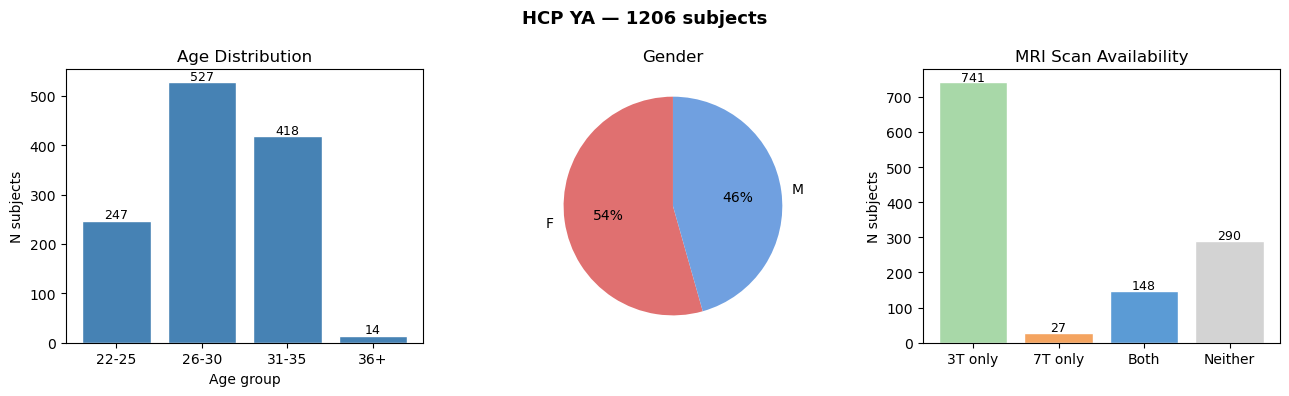

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

# Age distribution
age_order = ['22-25', '26-30', '31-35', '36+']
age_counts = df['Age'].value_counts().reindex(age_order)
axes[0].bar(age_order, age_counts.values, color='steelblue', edgecolor='white')
axes[0].set_title('Age Distribution')
axes[0].set_xlabel('Age group')
axes[0].set_ylabel('N subjects')
for i, v in enumerate(age_counts.values):
    axes[0].text(i, v + 5, str(v), ha='center', fontsize=9)

# Gender
g = df['Gender'].value_counts()
axes[1].pie(g.values, labels=g.index, autopct='%1.0f%%',
            colors=['#e07070', '#70a0e0'], startangle=90)
axes[1].set_title('Gender')

# Scan availability
scan_labels = ['3T only', '7T only', 'Both', 'Neither']
t3 = df['3T_Full_MR_Compl'] == True
t7 = df['7T_Full_MR_Compl'] == True
counts = [
    (t3 & ~t7).sum(),
    (~t3 & t7).sum(),
    (t3 & t7).sum(),
    (~t3 & ~t7).sum(),
]
colors = ['#a8d8a8', '#f4a460', '#5b9bd5', '#d3d3d3']
bars = axes[2].bar(scan_labels, counts, color=colors, edgecolor='white')
axes[2].set_title('MRI Scan Availability')
axes[2].set_ylabel('N subjects')
for bar, v in zip(bars, counts):
    axes[2].text(bar.get_x() + bar.get_width()/2, v + 5, str(v), ha='center', fontsize=9)

fig.suptitle(f'HCP YA — {len(df)} subjects', fontsize=13, fontweight='bold')
fig.tight_layout()
plt.show()

## 3. Cognitive Score Variables

### NIH Toolbox Battery

| Variable prefix | Task | What it measures |
|---|---|---|
| `PicSeq` | Picture Sequence Memory | Episodic memory |
| `CardSort` | Dimensional Change Card Sort | Cognitive flexibility |
| `Flanker` | Flanker Inhibitory Control | Attention / inhibition |
| `PMAT24` | Penn Matrix Test (24-item) | **Fluid intelligence** |
| `ReadEng` | Oral Reading Recognition | Crystallized intelligence |
| `PicVocab` | Picture Vocabulary | Crystallized intelligence |
| `ProcSpeed` | Pattern Comparison | Processing speed |
| `ListSort` | List Sorting Working Memory | Working memory |

Each task has `_Unadj` (raw norm score, mean=100) and `_AgeAdj` (age-corrected).

### Composite Scores

| Variable | Description |
|---|---|
| `CogFluidComp` | Fluid cognition composite (CardSort, Flanker, PMAT, ProcSpeed, ListSort) |
| `CogCrystalComp` | Crystallized cognition composite (ReadEng, PicVocab) |
| `CogTotalComp` | Total cognition composite |
| `CogEarlyComp` | Early childhood battery composite |

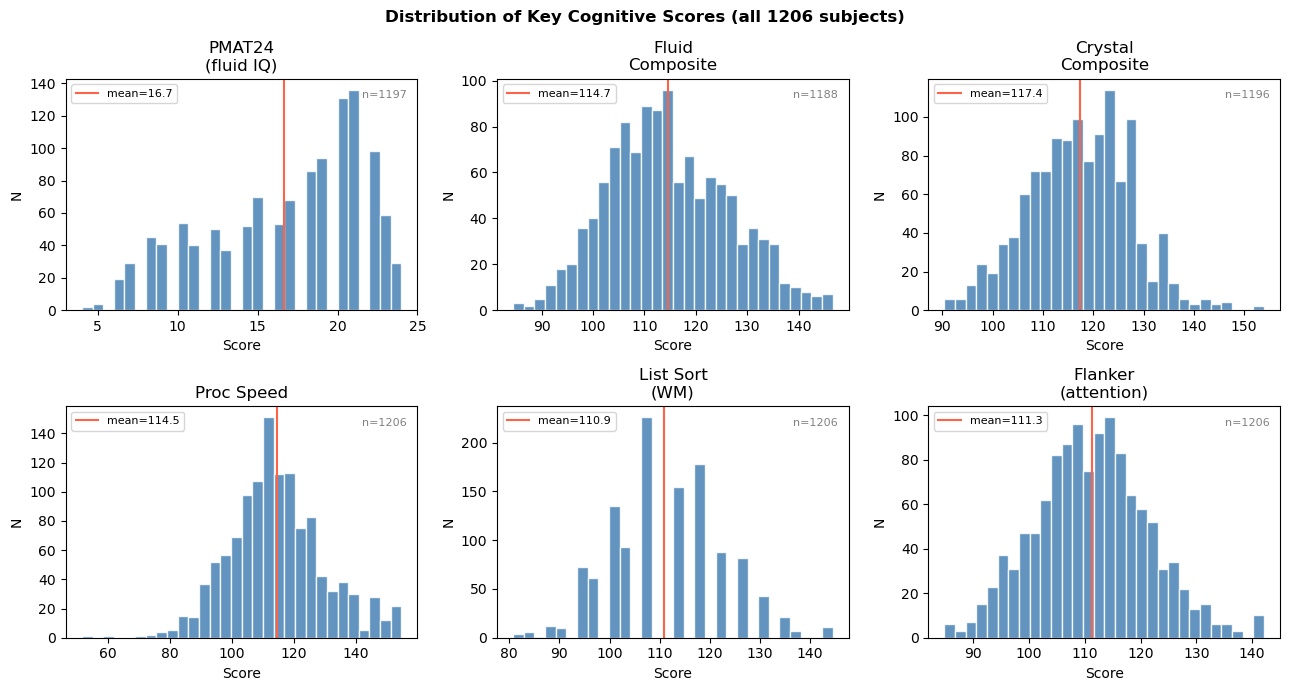

In [4]:
plot_scores = ['PMAT24_A_CR', 'CogFluidComp_Unadj', 'CogCrystalComp_Unadj',
               'ProcSpeed_Unadj', 'ListSort_Unadj', 'Flanker_Unadj']
labels = ['PMAT24\n(fluid IQ)', 'Fluid\nComposite', 'Crystal\nComposite',
          'Proc Speed', 'List Sort\n(WM)', 'Flanker\n(attention)']

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
axes = axes.flatten()

for ax, col, label in zip(axes, plot_scores, labels):
    data = df[col].dropna()
    ax.hist(data, bins=30, color='steelblue', edgecolor='white', alpha=0.85)
    ax.axvline(data.mean(), color='tomato', linewidth=1.5, label=f'mean={data.mean():.1f}')
    ax.set_title(label)
    ax.set_xlabel('Score')
    ax.set_ylabel('N')
    ax.legend(fontsize=8)
    ax.text(0.97, 0.95, f'n={len(data)}', transform=ax.transAxes,
            ha='right', va='top', fontsize=8, color='gray')

fig.suptitle('Distribution of Key Cognitive Scores (all 1206 subjects)', fontsize=12, fontweight='bold')
fig.tight_layout()
plt.show()

## 4. Subjects with 7T dMRI Data Available Locally

In [5]:
# Find subjects that have a local data folder
local_subjects = sorted([
    d for d in os.listdir(DATA_ROOT)
    if os.path.isdir(os.path.join(DATA_ROOT, d)) and d.isdigit()
])

print(f'Subjects with local dMRI data: {len(local_subjects)}')
print(local_subjects)

Subjects with local dMRI data: 11
['115017', '115825', '116726', '118225', '125525', '126426', '128935', '130518', '131217', '131722', '132118']


In [6]:
# Show what files are available per subject
DIFF_PATH = 'T1w/Diffusion_7T/'

records = []
for subj in local_subjects:
    diff_dir = os.path.join(DATA_ROOT, subj, DIFF_PATH)
    files = sorted(os.listdir(diff_dir)) if os.path.isdir(diff_dir) else []
    size_mb = {}
    for f in files:
        fp = os.path.join(diff_dir, f)
        if os.path.isfile(fp):
            size_mb[f] = round(os.path.getsize(fp) / 1e6, 1)
    records.append({'Subject': int(subj), **{f: size_mb.get(f, '') for f in
        ['bvals', 'bvecs', 'data.nii.gz', 'nodif_brain_mask.nii.gz', 'grad_dev.nii.gz']}})

file_df = pd.DataFrame(records).set_index('Subject')
print('File sizes (MB):')
file_df

File sizes (MB):


,bvals,bvecs,data.nii.gz,nodif_brain_mask.nii.gz,grad_dev.nii.gz
Subject,,,,,
115017,0.0,0.0,967.2,0.1,61.9
115825,0.0,0.0,1016.0,0.1,64.8
116726,0.0,0.0,1027.6,0.1,65.7
118225,0.0,0.0,1152.4,0.1,73.6
125525,0.0,0.0,911.0,0.1,58.3
126426,0.0,0.0,824.6,0.1,52.7
128935,0.0,0.0,1033.1,0.1,65.9
130518,0.0,0.0,902.6,0.1,57.7
131217,0.0,0.0,990.4,0.1,63.2


In [7]:
# Show cognitive scores for the 11 local subjects
local_ids = [int(s) for s in local_subjects]
local_df = df[df['Subject'].isin(local_ids)].set_index('Subject')

show_cols = ['Gender', 'Age', '7T_Full_MR_Compl',
             'PMAT24_A_CR', 'CogFluidComp_Unadj', 'CogCrystalComp_Unadj',
             'ListSort_Unadj', 'ProcSpeed_Unadj', 'Flanker_Unadj']
local_df[show_cols]

,Gender,Age,7T_Full_MR_Compl,PMAT24_A_CR,CogFluidComp_Unadj,CogCrystalComp_Unadj,ListSort_Unadj,ProcSpeed_Unadj,Flanker_Unadj
Subject,,,,,,,,,
115017,F,31-35,True,15.0,106.09,116.98,104.06,96.06,104.41
115825,M,22-25,True,9.0,98.46,95.14,104.06,89.64,112.21
116726,M,26-30,True,19.0,135.09,123.98,126.18,119.98,117.40
118225,M,26-30,True,23.0,123.88,126.22,130.38,99.14,115.38
125525,F,31-35,True,8.0,95.71,104.71,91.07,100.36,104.32
126426,F,31-35,True,7.0,123.17,104.22,108.06,145.54,103.78
128935,M,31-35,True,14.0,116.09,138.99,112.89,106.57,115.38
130518,F,31-35,True,9.0,111.09,116.20,96.99,133.26,111.75
131217,F,26-30,True,11.0,121.83,119.13,93.90,118.67,119.25


## 5. File Descriptions

Each subject folder (`dMRI/data/<subject_id>/T1w/Diffusion_7T/`) contains:

| File | Description |
|---|---|
| `data.nii.gz` | 4D dMRI volume — shape `(X, Y, Z, 143)`, one volume per gradient direction |
| `bvals` | b-values for each volume (mix of b≈0, b≈1000, b≈2000) |
| `bvecs` | Gradient direction vectors `(3, 143)` |
| `nodif_brain_mask.nii.gz` | Binary brain mask `(X, Y, Z)` — selects brain voxels only |
| `grad_dev.nii.gz` | Gradient deviation field — used for eddy-current correction (not used by NOFE) |

The `bvals` include b=0 (reference), b≈1000, and b≈2000 shells. The signal at each voxel is normalized by the mean b0 value before being fed into NOFE.

In [8]:
import nibabel as nib

example = local_subjects[0]
diff_dir = os.path.join(DATA_ROOT, example, DIFF_PATH)

bvals = np.loadtxt(diff_dir + 'bvals')
data  = nib.load(diff_dir + 'data.nii.gz')
mask  = nib.load(diff_dir + 'nodif_brain_mask.nii.gz')

print(f'Subject: {example}')
print(f'dMRI volume shape : {data.shape}   voxel size: {data.header.get_zooms()[:3]}')
print(f'Brain mask shape  : {mask.shape}')
print(f'Brain voxels      : {mask.get_fdata().astype(bool).sum():,}')
print(f'N gradient dirs   : {len(bvals)}')
print(f'b-values (unique) : {sorted(set(bvals.round(-1).astype(int)))}')

Subject: 115017
dMRI volume shape : (173, 207, 173, 143)   voxel size: (np.float32(1.05), np.float32(1.05), np.float32(1.05))
Brain mask shape  : (173, 207, 173)
Brain voxels      : 1,225,932
N gradient dirs   : 143
b-values (unique) : [np.int64(60), np.int64(980), np.int64(990), np.int64(1000), np.int64(1010), np.int64(1020), np.int64(1960), np.int64(1970), np.int64(1980), np.int64(1990), np.int64(2000), np.int64(2010), np.int64(2020)]


## 6. Missingness in Cognitive Scores (7T subjects)

In [9]:
df7 = df[df['7T_Full_MR_Compl'] == True].copy()

score_cols = cog_cols + cog_comp
missing = df7[score_cols].isna().mean().sort_values(ascending=False)
missing_pct = (missing * 100).round(1)

print(f'7T subjects: {len(df7)}')
print(f'Scores with any missing data:')
print(missing_pct[missing_pct > 0])
print(f'\nScores fully complete for all 7T subjects:')
print(list(missing_pct[missing_pct == 0].index))

7T subjects: 175
Scores with any missing data:
CogTotalComp_AgeAdj      2.9
CogTotalComp_Unadj       2.9
CogFluidComp_AgeAdj      2.9
CogFluidComp_Unadj       2.9
CogEarlyComp_AgeAdj      1.7
CogEarlyComp_Unadj       1.7
CogCrystalComp_AgeAdj    1.1
CogCrystalComp_Unadj     1.1
CardSort_Unadj           0.6
CardSort_AgeAdj          0.6
dtype: float64

Scores fully complete for all 7T subjects:
['PMAT24_A_CR', 'PMAT24_A_RTCR', 'PMAT24_A_SI', 'PicSeq_Unadj', 'ListSort_AgeAdj', 'PicSeq_AgeAdj', 'ProcSpeed_AgeAdj', 'ProcSpeed_Unadj', 'PicVocab_AgeAdj', 'PicVocab_Unadj', 'ReadEng_AgeAdj', 'ReadEng_Unadj', 'Flanker_AgeAdj', 'Flanker_Unadj', 'ListSort_Unadj']


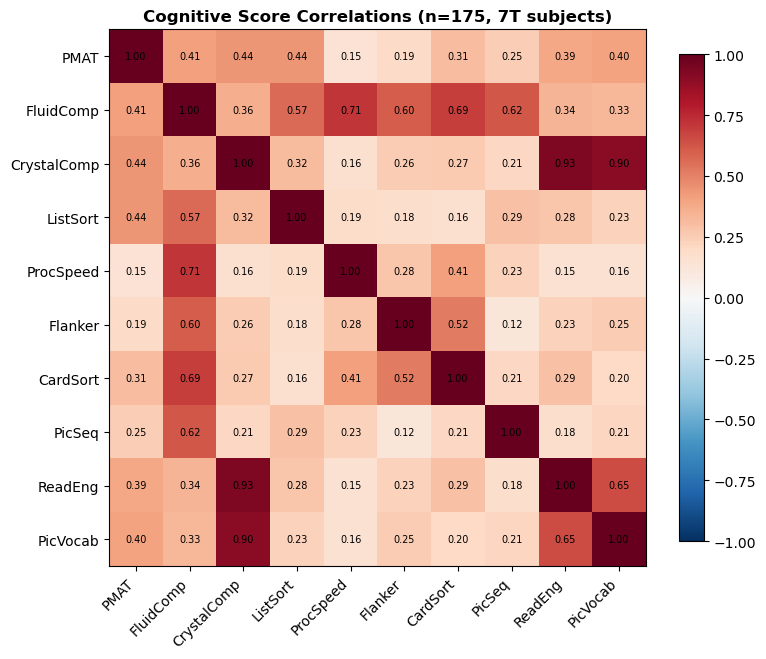

In [10]:
# Correlation matrix of key cognitive scores (7T subjects)
key = ['PMAT24_A_CR', 'CogFluidComp_Unadj', 'CogCrystalComp_Unadj',
       'ListSort_Unadj', 'ProcSpeed_Unadj', 'Flanker_Unadj',
       'CardSort_Unadj', 'PicSeq_Unadj', 'ReadEng_Unadj', 'PicVocab_Unadj']
corr = df7[key].corr()

short = ['PMAT', 'FluidComp', 'CrystalComp', 'ListSort', 'ProcSpeed',
         'Flanker', 'CardSort', 'PicSeq', 'ReadEng', 'PicVocab']

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(short))); ax.set_xticklabels(short, rotation=45, ha='right')
ax.set_yticks(range(len(short))); ax.set_yticklabels(short)
for i in range(len(short)):
    for j in range(len(short)):
        ax.text(j, i, f'{corr.values[i,j]:.2f}', ha='center', va='center', fontsize=7)
plt.colorbar(im, ax=ax, shrink=0.8)
ax.set_title('Cognitive Score Correlations (n=175, 7T subjects)', fontweight='bold')
fig.tight_layout()
plt.show()

## 7. Summary

- **1206 total subjects** in the HCP YA release
- **175 subjects** have complete 7T MRI data — all 175 have `PMAT24` scores
- **11 subjects** have dMRI data downloaded locally (see `dMRI/data/`)
- Each subject folder contains the 4D dMRI volume (143 directions), b-values/vectors, and brain mask
- The CSV also includes **FreeSurfer morphometry** (volumes, cortical thickness, surface area) for subjects with 3T data
- The primary cognitive target used for NOFE evaluation is **`PMAT24_A_CR`** (fluid intelligence, 0–24 correct answers)